## Tail frequency

Analyses tail-beat frequency (PSD, development).

Figures are saved to the project `figures/` directory and to `tail_frequency/media/`.

Import libraries:

In [1]:
import numpy as np
import matplotlib.pyplot as plt
def inline():
    %matplotlib inline
    plt.close('all')
def widget():
    %matplotlib widget
    plt.close('all')
import sys
from pathlib import Path
_code = Path.cwd() if (Path.cwd() / "paths.py").exists() else Path.cwd().parent
if str(_code.resolve()) not in [str(Path(p).resolve()) for p in sys.path]:
    sys.path.insert(0, str(_code.resolve()))
from paths import PROJECT_ROOT, DATA_DIR, FIGURES_DIR, notebook_media_dir
%load_ext autoreload
%autoreload 2
    
#from functions.visual_flow_behavior_plotting import *
from functions.visual_flow_behavior_analysis import *
#from functions.brain_analysis import *
from functions.utilities import *
#from functions.feedback_models import *
from functions.freely_swimming import *
from functions.MC_freely_swimming import *
from functions.MC_plots import *

import os
import h5py
from ipywidgets import interact,IntSlider
from scipy import fft
from scipy.ndimage import gaussian_filter
from skimage import io
import pickle
from scipy import fft
from sklearn.preprocessing import scale
from mpl_toolkits.axes_grid1.axes_divider import make_axes_locatable
from scipy.stats import iqr
import pandas as pd
from scipy.interpolate import interp1d

OMP: Info #276: omp_set_nested routine deprecated, please use omp_set_max_active_levels instead.


In [2]:
print(os.getcwd()) 

<repo>/code/tail_frequency


In [3]:
# Paths from code/paths.py (project root, data, figures, local media)
path = str(PROJECT_ROOT)
path_data = str(DATA_DIR)
path_figures = str(FIGURES_DIR)
path_media = str(notebook_media_dir("tail_frequency"))
print(path, path_data, path_figures)

<repo> <repo>/data <repo>/figures


In [4]:
from functions.MC_utilities import *
[color_y, color_m, color_o, color_low_boutID, color_med_boutID, color_high_boutID, color_cont, color_bout] = get_colors()
group_colors = [color_y, color_m, color_o]

#### Import data:

In [5]:
fish_ids_young=['13_06May24_1','13_30Oct24_3','13_30Oct24_4','14_27Mar24_1','14_31Oct24_1']
#fish_ids_young=['13_06May24_1','13_30Oct24_3','13_30Oct24_4','14_31Oct24_1']
index_y = list(range(0, len(fish_ids_young)))
print(index_y)

[0, 1, 2, 3, 4]


In [6]:
fish_ids_intermediate=['17_21May24_2','18_22May24_1','18_22May24_2','19_23May24_5','20_05Jun24_1','20_05Jun24_2','20_12Jun24_1','21_06Dec24_1','21_06Dec24_2','21_06Jun24_1','25_10Jun24_1']
index_i = list( range(len(fish_ids_young), len(fish_ids_young)+len(fish_ids_intermediate)) )
print(index_i)

[5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15]


In [7]:
fish_ids_old=['26_02May24_2','27_12Jun24_1','28_04May24_1','30_06May24_2','34_11Dec24_1','34_11Dec24_3']
#fish_ids_old=['26_02May24_2','28_04May24_1','30_06May24_2','34_11Dec24_1','34_11Dec24_3']
index_o = list( range( len(fish_ids_young)+len(fish_ids_intermediate) , len(fish_ids_young)+len(fish_ids_intermediate)+len(fish_ids_old) ) )
print(index_o)

[16, 17, 18, 19, 20, 21]


In [8]:
fish_ids=fish_ids_young+fish_ids_intermediate+fish_ids_old

In [9]:
fish_ids

['13_06May24_1',
 '13_30Oct24_3',
 '13_30Oct24_4',
 '14_27Mar24_1',
 '14_31Oct24_1',
 '17_21May24_2',
 '18_22May24_1',
 '18_22May24_2',
 '19_23May24_5',
 '20_05Jun24_1',
 '20_05Jun24_2',
 '20_12Jun24_1',
 '21_06Dec24_1',
 '21_06Dec24_2',
 '21_06Jun24_1',
 '25_10Jun24_1',
 '26_02May24_2',
 '27_12Jun24_1',
 '28_04May24_1',
 '30_06May24_2',
 '34_11Dec24_1',
 '34_11Dec24_3']

In [10]:
index_groups = {
    '1-2 wpf': index_y,
    '3 wpf': index_i,
    '4-5 wpf': index_o
}

In [11]:
age_list = [int(fid.split('_')[0]) for fid in fish_ids]
print(age_list)

[13, 13, 13, 14, 14, 17, 18, 18, 19, 20, 20, 20, 21, 21, 21, 25, 26, 27, 28, 30, 34, 34]


Load:

In [12]:
speed_clean = pd.read_hdf(os.path.join(path_data, f"speed_clean.h5"), key='df')

In [13]:
speed_clean

,ID,t_c,vfish_c,vtail_c,dangletail_c,angletail_c,freqtail_c,mean_thrust_c
0,13_06May24_1,0.000000,NaN,NaN,NaN,NaN,NaN,NaN
1,13_06May24_1,0.003333,NaN,NaN,NaN,NaN,NaN,NaN
2,13_06May24_1,0.006667,NaN,NaN,NaN,NaN,NaN,NaN
3,13_06May24_1,0.010000,NaN,NaN,NaN,NaN,NaN,NaN
4,13_06May24_1,0.013333,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...
21727813,34_11Dec24_3,320.736667,NaN,NaN,NaN,NaN,NaN,NaN
21727814,34_11Dec24_3,320.740000,NaN,NaN,NaN,NaN,NaN,NaN
21727815,34_11Dec24_3,320.743333,NaN,NaN,NaN,NaN,NaN,NaN
21727816,34_11Dec24_3,320.746667,NaN,NaN,NaN,NaN,NaN,NaN


In [14]:
thrust_thresholds = pd.read_hdf(os.path.join(path_data, f"thrust_thresholds.h5"), key='df')

In [15]:
thrust_thresholds

,ID,thrust_thr,mask_movetail
0,13_06May24_1,0.000331,False
1,13_06May24_1,0.000331,False
2,13_06May24_1,0.000331,False
3,13_06May24_1,0.000331,False
4,13_06May24_1,0.000331,False
...,...,...,...
21727813,34_11Dec24_3,0.025991,False
21727814,34_11Dec24_3,0.025991,False
21727815,34_11Dec24_3,0.025991,False
21727816,34_11Dec24_3,0.025991,False


In [16]:
onsets = pd.read_hdf(os.path.join(path_data, f"onsets.h5"), key='df')

In [17]:
onsets

,ID,onset_indices,initial_vfish,initial_vtail,bout_duration
0,13_06May24_1,1369,6.717492,102.127655,2.566667
1,13_06May24_1,2987,4.772649,90.986139,1.966667
2,13_06May24_1,4877,7.283671,136.008985,1.780000
3,13_06May24_1,5695,6.163918,100.164392,2.900000
4,13_06May24_1,6601,3.750249,69.222574,0.966667
...,...,...,...,...,...
45480,34_11Dec24_3,92811,24.794113,263.748909,0.213333
45481,34_11Dec24_3,92984,35.093076,348.691133,0.213333
45482,34_11Dec24_3,93206,38.267398,332.921438,0.196667
45483,34_11Dec24_3,93407,35.724430,275.439541,0.216667


In [18]:
t_c_list=[]
vfish_c_list=[]
vtail_c_list=[]
mean_thrust_c_list=[]
angletail_c_list=[]
dangletail_c_list=[]
freqtail_c_list=[]

for fish_ID in tqdm(fish_ids):
    speed_clean_fish=subset_by_fish(fish_ID,DF1=speed_clean)[0]
    t_c_list.append(speed_clean_fish['t_c'].values)
    vfish_c_list.append(speed_clean_fish['vfish_c'].values)
    vtail_c_list.append(speed_clean_fish['vtail_c'].values)    
    mean_thrust_c_list.append(speed_clean_fish['mean_thrust_c'].values)
    angletail_c_list.append(speed_clean_fish['angletail_c'].values)
    dangletail_c_list.append(speed_clean_fish['dangletail_c'].values)
    freqtail_c_list.append(speed_clean_fish['freqtail_c'].values)

  0%|          | 0/22 [00:00<?, ?it/s]

Subsetting data of the fish 13_06May24_1


  5%|▍         | 1/22 [00:03<01:04,  3.08s/it]

Subsetting data of the fish 13_30Oct24_3


  9%|▉         | 2/22 [00:06<01:00,  3.04s/it]

...

 91%|█████████ | 20/22 [01:05<00:06,  3.27s/it]

Subsetting data of the fish 34_11Dec24_1


 95%|█████████▌| 21/22 [01:08<00:03,  3.35s/it]

Subsetting data of the fish 34_11Dec24_3


100%|██████████| 22/22 [01:11<00:00,  3.27s/it]


In [19]:
thrust_thr_list=[]
mask_movetail_list=[]

for fish_ID in tqdm(fish_ids):
    thrust_thresholds_fish=subset_by_fish(fish_ID,DF1=thrust_thresholds)[0]
    thrust_thr_list.append(thrust_thresholds_fish['thrust_thr'].values[0])
    mask_movetail_list.append(thrust_thresholds_fish['mask_movetail'].values)

  0%|          | 0/22 [00:00<?, ?it/s]

Subsetting data of the fish 13_06May24_1


  5%|▍         | 1/22 [00:03<01:11,  3.41s/it]

Subsetting data of the fish 13_30Oct24_3


  9%|▉         | 2/22 [00:06<01:09,  3.46s/it]

...

 91%|█████████ | 20/22 [01:01<00:06,  3.01s/it]

Subsetting data of the fish 34_11Dec24_1


 95%|█████████▌| 21/22 [01:04<00:03,  3.10s/it]

Subsetting data of the fish 34_11Dec24_3


100%|██████████| 22/22 [01:07<00:00,  3.06s/it]


In [20]:
onset_indices_list=[]
initial_vfish_list=[]
initial_vtail_list=[]
bout_duration_list=[]
onset_times_list=[]

for fish_ID in tqdm(fish_ids):
    onsets_fish=subset_by_fish(fish_ID,DF1=onsets)[0]
    onset_indices_list.append(onsets_fish['onset_indices'].values)
    initial_vfish_list.append(onsets_fish['initial_vfish'].values)
    initial_vtail_list.append(onsets_fish['initial_vtail'].values)
    bout_duration_list.append(onsets_fish['bout_duration'].values)
    
for i in range(len(fish_ids)):  
    onset_times_list.append(t_c_list[i][onset_indices_list[i]])

100%|██████████| 22/22 [00:00<00:00, 147.85it/s]


Subsetting data of the fish 13_06May24_1
Subsetting data of the fish 13_30Oct24_3
Subsetting data of the fish 13_30Oct24_4
Subsetting data of the fish 14_27Mar24_1
Subsetting data of the fish 14_31Oct24_1
Subsetting data of the fish 17_21May24_2
Subsetting data of the fish 18_22May24_1
Subsetting data of the fish 18_22May24_2
Subsetting data of the fish 19_23May24_5
Subsetting data of the fish 20_05Jun24_1
Subsetting data of the fish 20_05Jun24_2
Subsetting data of the fish 20_12Jun24_1
Subsetting data of the fish 21_06Dec24_1
Subsetting data of the fish 21_06Dec24_2
Subsetting data of the fish 21_06Jun24_1
Subsetting data of the fish 25_10Jun24_1
Subsetting data of the fish 26_02May24_2
Subsetting data of the fish 27_12Jun24_1
Subsetting data of the fish 28_04May24_1
Subsetting data of the fish 30_06May24_2
Subsetting data of the fish 34_11Dec24_1
Subsetting data of the fish 34_11Dec24_3


## start some plots to visualize data

In [21]:
fish_ids

['13_06May24_1',
 '13_30Oct24_3',
 '13_30Oct24_4',
 '14_27Mar24_1',
 '14_31Oct24_1',
 '17_21May24_2',
 '18_22May24_1',
 '18_22May24_2',
 '19_23May24_5',
 '20_05Jun24_1',
 '20_05Jun24_2',
 '20_12Jun24_1',
 '21_06Dec24_1',
 '21_06Dec24_2',
 '21_06Jun24_1',
 '25_10Jun24_1',
 '26_02May24_2',
 '27_12Jun24_1',
 '28_04May24_1',
 '30_06May24_2',
 '34_11Dec24_1',
 '34_11Dec24_3']

20_12Jun24_1


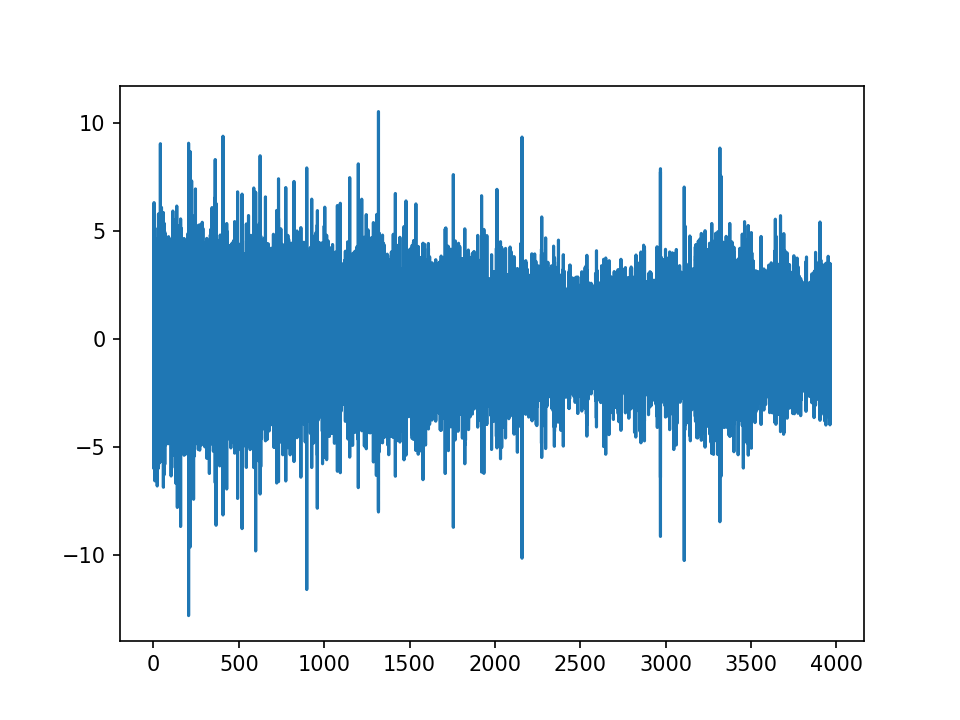

In [22]:
i=11

print(fish_ids[i])

dt=1/300
default()
widget()
fig,ax=plt.subplots(figsize=(6.4,4.8),dpi=150)
#ax.plot(t_c_list[i],vtail_c_list[i]/1000,'-')
ax.plot(t_c_list[i],dangletail_c_list[i]/10,'-')
#ax.plot(t_c_list[i],mean_thrust_c_list[i],'-')
#ax.axhline(thrust_thr_list[i],c='k')
#ax.plot(t_c_list[i][mask_movetail_list[i]], np.zeros(np.sum(mask_movetail_list[i])),'.')

#ax.plot(t_c_list[i],mask_movetail_list[i]/10,'-')

#ax.set_xlim(255,255.5)
plt.show()

## Freq tail - from Hilbert

In [23]:
freqtail_c_list

[array([nan, nan, nan, ..., nan, nan, nan]),
 array([nan, nan, nan, ..., nan, nan, nan]),
 array([        nan,         nan,         nan, ..., 29.49714032,
        35.42699243, 38.39026477]),
 array([nan, nan, nan, ..., nan, nan, nan]),
 array([        nan,         nan,         nan, ..., 30.06133387,
        38.22660959, 44.23419751]),
 array([nan, nan, nan, ..., nan, nan, nan]),
 array([nan, nan, nan, ..., nan, nan, nan]),
 array([        nan,         nan,         nan, ..., 17.56696359,
         6.14796673,  3.30292516]),
 array([nan, nan, nan, ..., nan, nan, nan]),
 array([nan, nan, nan, ..., nan, nan, nan]),
 array([nan, nan, nan, ..., nan, nan, nan]),
 array([nan, nan, nan, ..., nan, nan, nan]),
 array([        nan,         nan,         nan, ..., 19.67875268,
        15.0538546 , 20.03308934]),
 array([        nan,         nan,         nan, ..., 42.87127683,
        35.33334338, 39.34455156]),
 array([nan, nan, nan, ..., nan, nan, nan]),
 array([nan, nan, nan, ..., nan, nan, nan]),


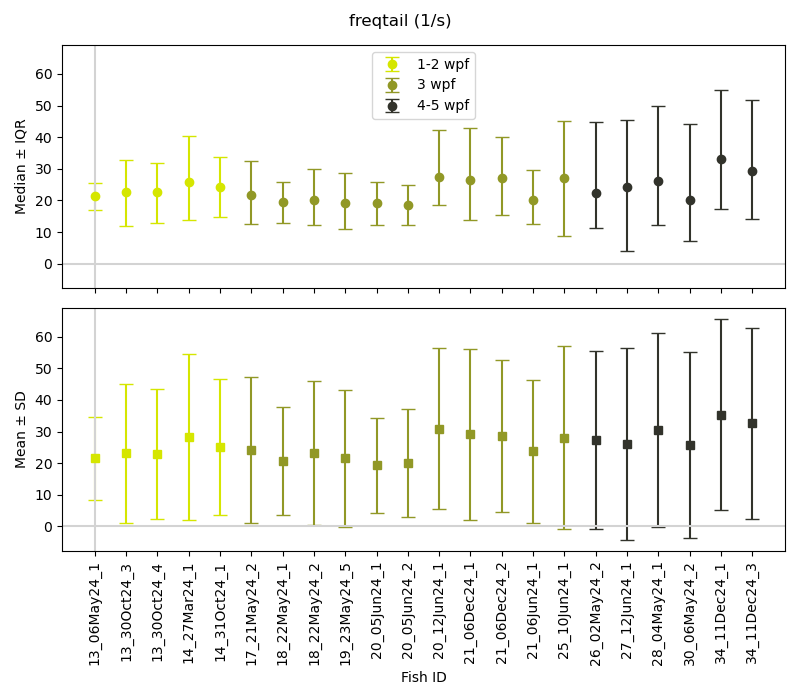

In [24]:
plot_pdf_errorbars_median_and_mean(freqtail_c_list, fish_ids, index_groups, group_colors, title='freqtail (1/s)')

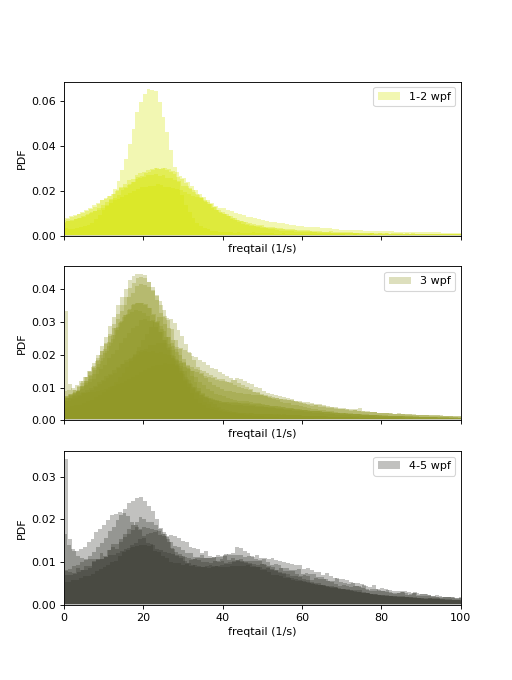

In [25]:
plot_hist_dpf_three_subplots(freqtail_c_list, index_groups, group_colors, xlabel='freqtail (1/s)', xlim=(0,100), nbins=300)

## Freq tail -  spectral density of dtheta

In [26]:
from functions.visual_flow_behavior_analysis import *

In [27]:
def get_nan_free_segments(signal, times, min_length=300):
    isnan = np.isnan(signal)
    segments = []
    start = None
    for i, nan in enumerate(isnan):
        if not nan and start is None:
            start = i
        elif nan and start is not None:
            if i - start >= min_length:
                segments.append((start, i))
            start = None
    if start is not None and len(signal) - start >= min_length:
        segments.append((start, len(signal)))
    return segments

In [28]:
results = {}  # Dictionary to store outputs per fish

for i in range(len(fish_ids)):  # Adjust range if needed
    fish_id = fish_ids[i]
    signal = dangletail_c_list[i]
    times = t_c_list[i]

    # --- Get non-NaN segments ---
    segments = get_nan_free_segments(signal, times)

    # --- Welch parameters ---
    fs = 1 / np.mean(np.diff(times))
    window_length = 1.0  # seconds

    # --- Compute PSD on each valid segment ---
    spectra = []
    for start, end in segments:
        seg_signal = signal[start:end]
        seg_times = times[start:end]
        freqs, psd = calculate_fourier_spectrum_welch(seg_signal, times=seg_times, fs=fs, window_length=window_length)
        spectra.append(psd)

    if len(spectra) == 0:
        print(f"⚠️ No valid segments for fish {fish_id}")
        continue

    # --- Average PSD and SEM ---
    spectra = np.stack(spectra, axis=0)
    psd_avg = np.nanmean(spectra, axis=0)
    psd_sem = np.nanstd(spectra, axis=0) / np.sqrt(spectra.shape[0])

    # --- Peak extraction ---
    peak_idx = np.argmax(psd_avg)
    peak_freq = freqs[peak_idx]
    peak_power = psd_avg[peak_idx]
    peak_power_sem = psd_sem[peak_idx]

    # --- Save results ---
    results[fish_id] = {
        "freqs": freqs,
        "psd_avg": psd_avg,
        "psd_sem": psd_sem,
        "peak_frequency_Hz": peak_freq,
        "peak_power": peak_power,
        "power_sem": peak_power_sem,
    }

    print(f"[{fish_id}] Peak Frequency: {peak_freq:.2f} Hz — Power: {peak_power:.3e} ± {peak_power_sem:.3e}")

[13_06May24_1] Peak Frequency: 22.00 Hz — Power: 3.219e+01 ± 2.695e+00
[13_30Oct24_3] Peak Frequency: 18.00 Hz — Power: 5.798e+00 ± 3.454e-01
[13_30Oct24_4] Peak Frequency: 19.00 Hz — Power: 1.307e+01 ± 6.866e-01
[14_27Mar24_1] Peak Frequency: 20.00 Hz — Power: 2.274e+01 ± 6.240e+00
[14_31Oct24_1] Peak Frequency: 21.00 Hz — Power: 7.263e+00 ± 4.426e-01
[17_21May24_2] Peak Frequency: 20.00 Hz — Power: 6.062e+00 ± 2.918e-01
[18_22May24_1] Peak Frequency: 18.00 Hz — Power: 9.100e+00 ± 1.952e-01
[18_22May24_2] Peak Frequency: 18.00 Hz — Power: 8.728e+00 ± 1.854e-01
[19_23May24_5] Peak Frequency: 17.00 Hz — Power: 6.339e+00 ± 1.253e-01
[20_05Jun24_1] Peak Frequency: 18.00 Hz — Power: 1.554e+01 ± 4.855e-01
[20_05Jun24_2] Peak Frequency: 17.00 Hz — Power: 1.550e+01 ± 4.544e-01
[20_12Jun24_1] Peak Frequency: 24.00 Hz — Power: 7.860e+00 ± 2.916e-01
[21_06Dec24_1] Peak Frequency: 19.00 Hz — Power: 4.591e+00 ± 2.932e-01
[21_06Dec24_2] Peak Frequency: 22.00 Hz — Power: 4.561e+00 ± 2.779e-01
[21_06

/var/folders/xl/ytwdm9h57dd5l_2fzzwzj7hw0000gn/T/ipykernel_11577/1354199457.py:8: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = cm.get_cmap("viridis", n_fish)


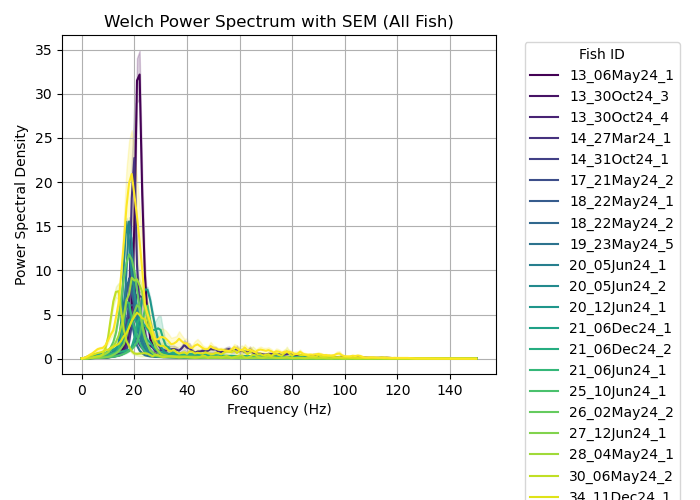

In [29]:
import matplotlib.pyplot as plt
import matplotlib.cm as cm

# Assuming `results` is a dictionary with PSD data per fish
# Each entry: results[fish_id] = {"freqs": ..., "psd_avg": ..., "psd_sem": ...}

n_fish = len(results)
cmap = cm.get_cmap("viridis", n_fish)
fish_ids = list(results.keys())

plt.figure(figsize=(7, 5))
for i, fish_id in enumerate(fish_ids):
    res = results[fish_id]
    f = res["freqs"]
    avg = res["psd_avg"]
    sem = res["psd_sem"]
    color = cmap(i)
    
    plt.plot(f, avg, label=fish_id, color=color)
    plt.fill_between(f, avg - sem, avg + sem, alpha=0.2, color=color)

plt.xlabel("Frequency (Hz)")
plt.ylabel("Power Spectral Density")
plt.title("Welch Power Spectrum with SEM (All Fish)")
plt.grid(True)
plt.legend(title="Fish ID", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

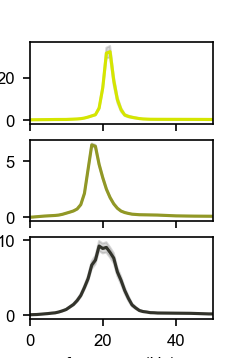

In [30]:
default()
widget()
arial()

cm_to_inch = 1 / 2.54
fig_width_cm = 4*1
fig_height_cm = 4.05*1.5

fig, axes = plt.subplots(3, 1, figsize=(fig_width_cm * cm_to_inch, fig_height_cm * cm_to_inch),   dpi=150, sharex=True)

# Select valid indices
selected_indices = [0, 14, 18]
selected_fish_ids = [fish_ids[i] for i in selected_indices]

j = 0
for ax, fish_id in zip(axes, selected_fish_ids):
    res = results[fish_id]
    f = res["freqs"]
    avg = res["psd_avg"]
    sem = res["psd_sem"]

    ax.plot(f, avg, color = group_colors[j], label=f"{fish_id}")
    ax.fill_between(f, avg - sem, avg + sem, color = 'gray', alpha=0.3)
    #ax.set_yticks([])
    ax.set_ylabel(r'PSD of $\dot\theta$')#ax.set_ylabel(r'spectral density of $\dot\theta$')
    #ax.set_title(f"Fish {fish_id}")
    #ax.set_yscale("log")  
    #ax.grid(True)
    j = j + 1
    #ax.legend()

axes[-1].set_xlabel("frequency (Hz)")
plt.xlim(0,50)


fig.savefig(os.path.join(path_figures, "Fig_S2f_tail_frequency_PSD_examples.pdf"), format="pdf")
fig.savefig(os.path.join(path_media, "Fig_S2f_tail_frequency_PSD_examples.pdf"), format="pdf", bbox_inches='tight', dpi=200)

plt.show()

# statistics: tail_frequency_development

In [31]:
from scipy.stats import mannwhitneyu
import itertools

group_names = list(index_groups.keys())

# --- Compute peak frequencies per fish ---
fish_ids = list(results.keys())
group_data = []

for group in group_names:
    indices = index_groups[group]
    freqs_group = []
    for i in indices:
        fish_id = fish_ids[i]
        freqs = results[fish_id]["freqs"]
        psd_avg = results[fish_id]["psd_avg"]
        peak_freq = freqs[np.argmax(psd_avg)]
        freqs_group.append(peak_freq)
    group_data.append(freqs_group)

# --- Perform pairwise Mann-Whitney U tests ---
p_values = {}
for (i, g1), (j, g2) in itertools.combinations(enumerate(group_names), 2):
    stat, p = mannwhitneyu(group_data[i], group_data[j], alternative='two-sided')
    p_values[(g1, g2)] = p

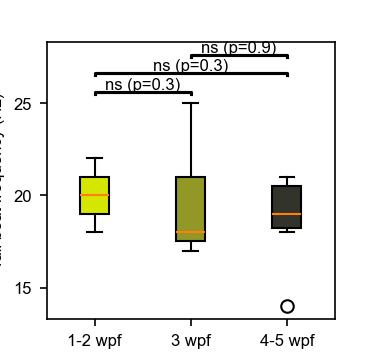

In [32]:
# --- Plot boxplot ---
#plt.figure(figsize=(6, 4))

default()
widget()
arial()

cm_to_inch = 1 / 2.54
fig_width_cm = 4.2*1.5
fig_height_cm = 4.05*1.5

fig = plt.figure(figsize=(fig_width_cm * cm_to_inch, fig_height_cm * cm_to_inch),   dpi=150)


bplot = plt.boxplot(group_data, patch_artist=True, labels=group_names)

# Color boxes
for patch, color in zip(bplot['boxes'], group_colors):
    patch.set_facecolor(color)

# --- Annotate statistical tests ---
y_max = max(max(g) for g in group_data) + 0.5
step = 1
for idx, ((g1, g2), p) in enumerate(p_values.items()):
    x1 = group_names.index(g1) + 1
    x2 = group_names.index(g2) + 1
    y = y_max + idx * step

    plt.plot([x1, x1, x2, x2], [y, y+0.1, y+0.1, y], lw=1.5, color='black')
    if p > 0.05:
        label = 'ns'
    elif p <= 0.001:
        label = '***'
    elif p <= 0.01:
        label = '**'
    else:
        label = '*'
    plt.text((x1 + x2) / 2, y + 0.1, f"{label} (p={p:.1f})", ha='center', va='bottom')


# --- Final formatting ---
plt.ylabel("Tail beat frequency (Hz)")

plt.yticks([15, 20, 25]) #Hz

fig.savefig(os.path.join(path_figures, "Fig_S2g_tail_frequency_development.pdf"), format="pdf")
fig.savefig(os.path.join(path_media, "Fig_S2g_tail_frequency_development.pdf"), format="pdf", bbox_inches='tight', dpi=200)

plt.show()
